# Si la UTB tuviera 100 estudiantes
## Calidad de sueño y su impacto en el rendimiento académico

**Asignatura:** Introducción a Ciencia de Datos · **Profesor:** David Sierra Porta
**Integrantes:** Maria Jose Barrientos Aldana · Nerlis Otero · Elian Perea

---

**Pregunta:** si la UTB tuviera 100 estudiantes, ¿cómo sería su calidad de sueño y qué impacto tendría en su rendimiento académico?

**Pasos de este análisis**
1. Cargar y limpiar los datos
2. Describir a los 100 estudiantes (¿cómo son y cómo duermen?)
3. Cruzar variables (¿el sueño se relaciona con el cansancio y el rendimiento?)
4. Medir la relación con correlaciones
5. Conclusiones y limitaciones

> Como son exactamente 100 estudiantes, **cada número es también un porcentaje**: "26 estudiantes" es lo mismo que "26 de cada 100".

## 1. Cargar y limpiar los datos

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Liberation Serif", "DejaVu Serif"]
plt.rcParams["figure.dpi"] = 100

El archivo de Forms viene separado por **punto y coma** (`;`) y con codificación **latin-1**, por eso se indican en `read_csv`.

In [2]:
datos = pd.read_csv("Si la UTB tuviera 100 estudiantes(Sheet1).csv", sep=";", encoding="latin-1")
print("Filas y columnas:", datos.shape)
datos.head()

Filas y columnas: (106, 25)


,Id,Hora de inicio,Hora de finalización,Correo electrónico,Nombre,Edad,¿Con qué género te identificas?,¿Qué programa académico estás cursando actualmente?,¿Cuántas horas duermes por noche?,¿Cómo calificas tu calidad de sueño?,...,"¿Cómo organizas tu tiempo de estudio, ya sea para algún examen próximo, exposición o\ntrabajo que debas entregar?",¿Con qué frecuencia te trasnochas para estudiar para un examen o terminar algún trabajo?,¿A qué hora te acuestas normalmente cuando tienes clases al día siguiente?,¿Por cuánto tiempo utilizas el celular antes de dormir?,"¿Cuánto tiempo tardas diariamente en el transporte (moto, taxi, Uber, Transcaribe, etc.)\ndesde tu casa hasta la universidad y viceversa?",¿Realizas algún hobbie?,"Según la pregunta anterior, ¿cuál sería el hobbie que realizas?",¿Cuál es tu promedio académico del semestre anterior?,"Con qué frecuencia has faltado a clase, llegado tarde o te has quedado dormido/a en clase por falta de sueño?","¿Con qué frecuencia consumes café, bebidas energéticas u otros estimulantes para mantenerte despierto/a?"
0,1,04/11/2026 9:43,04/11/2026 9:45,anonymous,NaN,Entre 18 y 22 años,Femenino,Ingeniería de Sistemas y Computación,De 5 a 7 horas,Regular,...,Planifico algunas actividades,Algunas veces,Entre las 9:00 y las 11:00 p. m.,15 minutos,Entre 1 hora y 2 horas,Algunas veces,Coser o hacer crochet,Entre 3.6 y 4.0,Algunas veces,Todos los días
1,2,04/11/2026 9:44,04/11/2026 9:49,anonymous,NaN,Entre 18 y 22 años,Masculino,Ingeniería de Sistemas y Computación,De 5 a 7 horas,Regular,...,Estudio cuando tengo tiempo libre,Algunas veces,Entre las 11:00 p. m. y la 1:00 a. m.,1 hora,Menos de 30 minutos en total,Algunas veces,Leer,Entre 4.1 y 4.5,Algunas veces,Nunca
2,3,04/11/2026 9:46,04/11/2026 9:50,anonymous,NaN,Entre 18 y 22 años,Masculino,Ingeniería de Sistemas y Computación,De 5 a 7 horas,Regular,...,Estudio a última hora,Algunas veces,Entre las 11:00 p. m. y la 1:00 a. m.,Más de 1 hora,De 30 minutos a 1 hora,Algunas veces,Escuchar música,Entre 3.0 y 3.5,Algunas veces,Nunca
3,4,04/11/2026 9:47,04/11/2026 9:52,anonymous,NaN,Entre 18 y 22 años,Masculino,Psicología,Menos de 5 horas,Muy mala,...,Planifico algunas actividades,Casi siempre,Entre las 11:00 p. m. y la 1:00 a. m.,30 minutos,Entre 1 hora y 2 horas,Algunas veces,Escuchar música,Entre 3.6 y 4.0,Algunas veces,Todos los días
4,5,04/11/2026 9:50,04/11/2026 9:53,anonymous,NaN,Entre 18 y 22 años,Masculino,Ingeniería Eléctrica,De 5 a 7 horas,Regular,...,Planifico algunas actividades,Algunas veces,Entre las 9:00 y las 11:00 p. m.,1 hora,Entre 1 hora y 2 horas,Sí,Practicar un deporte,Entre 4.1 y 4.5,Algunas veces,Nunca


Se recibieron **106 respuestas**, pero el estudio es de **100 estudiantes**. Nos quedamos con las **100 primeras** (Id 1 a 100), que son las que llegaron primero. Además, cambiamos los nombres largos de las columnas por nombres cortos.

In [ ]:

datos.columns = ["id", "inicio", "fin", "correo", "nombre", "edad", "genero", "programa", "horas", "calidad",
                 "cansancio", "impacto", "factor", "estudia_freq", "estudia_tiempo", "organiza", "trasnocho",
                 "hora_acostarse", "celular", "transporte", "hobbie_si", "hobbie_cual", "promedio", "faltas", "cafeina"]


df = datos[datos["id"] <= 100].copy()
df = df.drop(columns=["id", "inicio", "fin", "correo", "nombre"])
print("Estudiantes en el análisis:", len(df))

Estudiantes en el análisis: 100


**Datos faltantes:** miramos cuántas respuestas vacías hay en cada pregunta. Además, en el promedio hay personas que escribieron *"Prefiero no responder"*; lo tratamos como dato vacío.

In [4]:
df["promedio"] = df["promedio"].replace("Prefiero no responder", np.nan)

vacios = df.isna().sum()
vacios[vacios > 0]

programa          1
horas             1
trasnocho         1
hora_acostarse    1
celular           1
transporte        1
hobbie_si         2
hobbie_cual       6
promedio          9
faltas            1
dtype: int64

Para que las tablas y gráficas sean más fáciles de leer, **acortamos algunos textos** de las respuestas.

In [5]:
df["horas"] = df["horas"].replace({"Menos de 5 horas": "Menos de 5 h", "De 5 a 7 horas": "5 a 7 h",
                                   "De 7 a 9 horas": "7 a 9 h", "Más de 9 horas": "Más de 9 h"})

df["hora_acostarse"] = df["hora_acostarse"].replace({
    "A las 9:00 p. m.": "9 p. m.", "Entre las 9:00 y las 11:00 p. m.": "9 a 11 p. m.",
    "Entre las 11:00 p. m. y la 1:00 a. m.": "11 p. m. a 1 a. m.",
    "Entre la 1:00 a. m. y las 3:00 a. m.": "1 a 3 a. m.", "Entre las 3:00 a. m. y las 5:00 a. m.": "3 a 5 a. m."})

df["celular"] = df["celular"].replace({"15 minutos": "15 min", "30 minutos": "30 min",
                                       "1 hora": "1 h", "Más de 1 hora": "Más de 1 h"})

df["promedio"] = df["promedio"].replace({"Entre 3.0 y 3.5": "3.0 a 3.5", "Entre 3.6 y 4.0": "3.6 a 4.0",
                                         "Entre 4.1 y 4.5": "4.1 a 4.5"})
df.head()

,edad,genero,programa,horas,calidad,cansancio,impacto,factor,estudia_freq,estudia_tiempo,organiza,trasnocho,hora_acostarse,celular,transporte,hobbie_si,hobbie_cual,promedio,faltas,cafeina
0,Entre 18 y 22 años,Femenino,Ingeniería de Sistemas y Computación,5 a 7 h,Regular,Algunas veces,Me cuesta mucho concentrarme,Los trabajos y las tareas,Algunas veces,Entre 1 y 3 horas,Planifico algunas actividades,Algunas veces,9 a 11 p. m.,15 min,Entre 1 hora y 2 horas,Algunas veces,Coser o hacer crochet,3.6 a 4.0,Algunas veces,Todos los días
1,Entre 18 y 22 años,Masculino,Ingeniería de Sistemas y Computación,5 a 7 h,Regular,Algunas veces,Me cuesta aprender,El uso del celular,Algunas veces,Entre 1 y 3 horas,Estudio cuando tengo tiempo libre,Algunas veces,11 p. m. a 1 a. m.,1 h,Menos de 30 minutos en total,Algunas veces,Leer,4.1 a 4.5,Algunas veces,Nunca
2,Entre 18 y 22 años,Masculino,Ingeniería de Sistemas y Computación,5 a 7 h,Regular,Algunas veces,Me cuesta mucho concentrarme,El uso del celular,Algunas veces,1 hora,Estudio a última hora,Algunas veces,11 p. m. a 1 a. m.,Más de 1 h,De 30 minutos a 1 hora,Algunas veces,Escuchar música,3.0 a 3.5,Algunas veces,Nunca
3,Entre 18 y 22 años,Masculino,Psicología,Menos de 5 h,Muy mala,Muchas veces,Me cuesta mucho concentrarme,Los trabajos y las tareas,Siempre,1 hora,Planifico algunas actividades,Casi siempre,11 p. m. a 1 a. m.,30 min,Entre 1 hora y 2 horas,Algunas veces,Escuchar música,3.6 a 4.0,Algunas veces,Todos los días
4,Entre 18 y 22 años,Masculino,Ingeniería Eléctrica,5 a 7 h,Regular,Algunas veces,No afecta mi rendimiento,Problemas personales,Algunas veces,1 hora,Planifico algunas actividades,Algunas veces,9 a 11 p. m.,1 h,Entre 1 hora y 2 horas,Sí,Practicar un deporte,4.1 a 4.5,Algunas veces,Nunca


## 2. Describir a los 100 estudiantes

### 2.1 ¿Quiénes son?

In [6]:
print(df["edad"].value_counts(), "\n")
print(df["genero"].value_counts(), "\n")
print(df["programa"].value_counts().head(8))

edad
Entre 18 y 22 años    87
17 años                8
Entre 23 y 35 años     4
Mayor de 35 años       1
Name: count, dtype: int64 

genero
Femenino      59
Masculino     39
No binario     2
Name: count, dtype: int64 

programa
Ingeniería de Sistemas y Computación    17
Psicología                              12
Finanzas y Negocios Internacionales     12
Ingeniería Mecatrónica                   9
Ingeniería Biomédica                     9
Ingeniería Industrial                    6
Diseño                                   6
Ingeniería Electrónica                   3
Name: count, dtype: int64


### 2.2 ¿Cómo duermen?

Definimos el **orden de las respuestas** (de menor a mayor) para que las gráficas salgan ordenadas y no al azar.

In [ ]:
orden_horas = ["Menos de 5 h", "5 a 7 h", "7 a 9 h", "Más de 9 h"]
orden_calidad = ["Muy mala", "Regular", "Buena", "Muy buena"]
orden_cansancio = ["Nunca", "Algunas veces", "Muchas veces", "Siempre"]
orden_hora = ["9 p. m.", "9 a 11 p. m.", "11 p. m. a 1 a. m.", "1 a 3 a. m.", "3 a 5 a. m."]

horas = df["horas"].value_counts().reindex(orden_horas)
calidad = df["calidad"].value_counts().reindex(orden_calidad)
cansancio = df["cansancio"].value_counts().reindex(orden_cansancio)
hora = df["hora_acostarse"].value_counts().reindex(orden_hora)

print(horas, "\n"); print(calidad, "\n"); print(cansancio, "\n"); print(hora)

horas
Menos de 5 h    26
5 a 7 h         65
7 a 9 h          7
Más de 9 h       1
Name: count, dtype: int64 

calidad
Muy mala     19
Regular      50
Buena        23
Muy buena     8
Name: count, dtype: int64 

cansancio
Nunca             3
Algunas veces    50
Muchas veces     32
Siempre          15
Name: count, dtype: int64 

hora_acostarse
9 p. m.                5
9 a 11 p. m.          25
11 p. m. a 1 a. m.    47
1 a 3 a. m.           18
3 a 5 a. m.            4
Name: count, dtype: int64


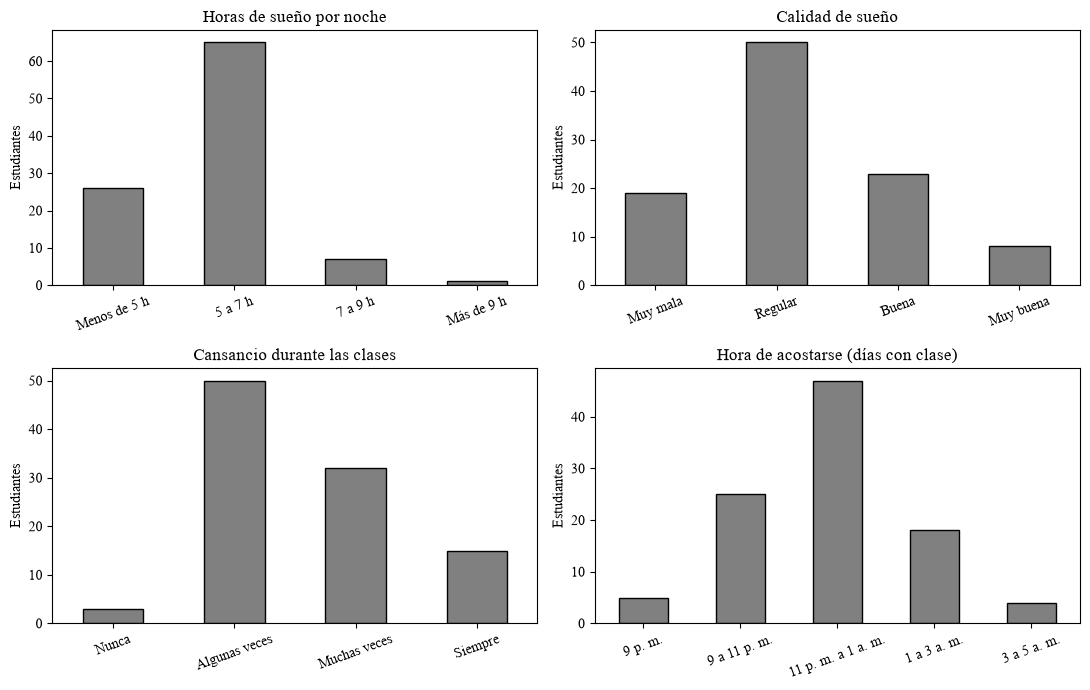

In [8]:
fig, ejes = plt.subplots(2, 2, figsize=(11, 7))

horas.plot(kind="bar", ax=ejes[0, 0], color="gray", edgecolor="black", title="Horas de sueño por noche")
calidad.plot(kind="bar", ax=ejes[0, 1], color="gray", edgecolor="black", title="Calidad de sueño")
cansancio.plot(kind="bar", ax=ejes[1, 0], color="gray", edgecolor="black", title="Cansancio durante las clases")
hora.plot(kind="bar", ax=ejes[1, 1], color="gray", edgecolor="black", title="Hora de acostarse (días con clase)")

for eje in ejes.ravel():
    eje.set_xlabel(""); eje.set_ylabel("Estudiantes")
    eje.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

**¿Cuántos de cada 100?** Calculamos algunos porcentajes clave (sobre las respuestas válidas).

In [ ]:

n_horas = df["horas"].notna().sum()
n_calidad = df["calidad"].notna().sum()
n_cansancio = df["cansancio"].notna().sum()

dormir_poco = df["horas"].isin(["Menos de 5 h", "5 a 7 h"]).sum() / n_horas * 100
menos_5 = (df["horas"] == "Menos de 5 h").sum() / n_horas * 100
calidad_baja = df["calidad"].isin(["Regular", "Muy mala"]).sum() / n_calidad * 100
cansados = df["cansancio"].isin(["Muchas veces", "Siempre"]).sum() / n_cansancio * 100

print(f"De cada 100 estudiantes, {menos_5:.0f} duermen menos de 5 horas.")
print(f"De cada 100 estudiantes, {dormir_poco:.0f} duermen menos de 7 horas.")
print(f"De cada 100 estudiantes, {calidad_baja:.0f} califican su calidad de sueño como regular o muy mala.")
print(f"De cada 100 estudiantes, {cansados:.0f} se sienten cansados en clase muchas veces o siempre.")

De cada 100 estudiantes, 26 duermen menos de 5 horas.
De cada 100 estudiantes, 92 duermen menos de 7 horas.
De cada 100 estudiantes, 69 califican su calidad de sueño como regular o muy mala.
De cada 100 estudiantes, 47 se sienten cansados en clase muchas veces o siempre.


### 2.3 ¿Cómo afecta el cansancio al rendimiento y qué les quita el sueño?

impacto
Me cuesta mucho concentrarme                   58
No afecta mi rendimiento                       16
Me cuesta aprender                             14
Afecta considerablemente mis calificaciones    12
Name: count, dtype: int64 

factor
Los trabajos y las tareas      29
Los exámenes y evaluaciones    29
El uso del celular             17
Problemas personales           12
Los horarios de clases          9
El transporte                   4
Name: count, dtype: int64


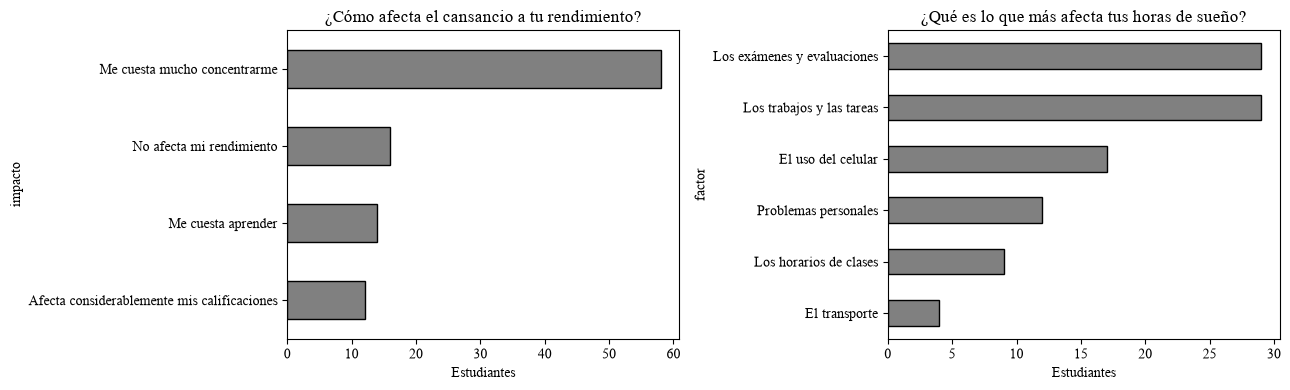

In [10]:
impacto = df["impacto"].value_counts()
factor = df["factor"].value_counts()
print(impacto, "\n"); print(factor)

fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
impacto.sort_values().plot(kind="barh", ax=ejes[0], color="gray", edgecolor="black",
                           title="¿Cómo afecta el cansancio a tu rendimiento?")
factor.sort_values().plot(kind="barh", ax=ejes[1], color="gray", edgecolor="black",
                          title="¿Qué es lo que más afecta tus horas de sueño?")
for eje in ejes: eje.set_xlabel("Estudiantes")
plt.tight_layout()
plt.show()

### 2.4 Hábitos: trasnocho, celular y estimulantes

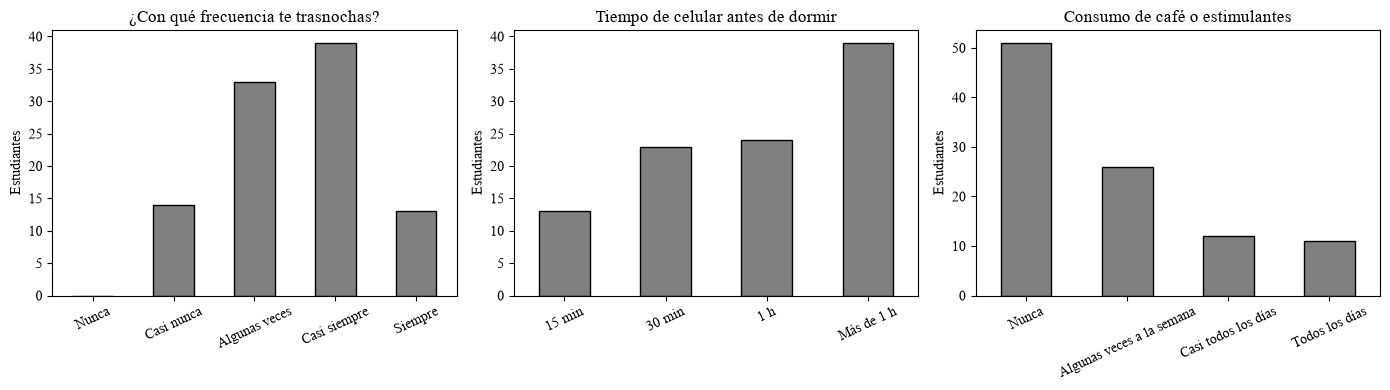

trasnocho
Nunca             NaN
Casi nunca       14.0
Algunas veces    33.0
Casi siempre     39.0
Siempre          13.0
Name: count, dtype: float64 

celular
15 min        13
30 min        23
1 h           24
Más de 1 h    39
Name: count, dtype: int64 

cafeina
Nunca                        51
Algunas veces a la semana    26
Casi todos los días          12
Todos los días               11
Name: count, dtype: int64


In [11]:
orden_trasnocho = ["Nunca", "Casi nunca", "Algunas veces", "Casi siempre", "Siempre"]
orden_celular = ["15 min", "30 min", "1 h", "Más de 1 h"]
orden_cafeina = ["Nunca", "Algunas veces a la semana", "Casi todos los días", "Todos los días"]

trasnocho = df["trasnocho"].value_counts().reindex(orden_trasnocho)
celular = df["celular"].value_counts().reindex(orden_celular)
cafeina = df["cafeina"].value_counts().reindex(orden_cafeina)

fig, ejes = plt.subplots(1, 3, figsize=(14, 4))
trasnocho.plot(kind="bar", ax=ejes[0], color="gray", edgecolor="black", title="¿Con qué frecuencia te trasnochas?")
celular.plot(kind="bar", ax=ejes[1], color="gray", edgecolor="black", title="Tiempo de celular antes de dormir")
cafeina.plot(kind="bar", ax=ejes[2], color="gray", edgecolor="black", title="Consumo de café o estimulantes")
for eje in ejes:
    eje.set_xlabel(""); eje.set_ylabel("Estudiantes"); eje.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

print(trasnocho, "\n"); print(celular, "\n"); print(cafeina)

### 2.5 Rendimiento académico

promedio
3.0 a 3.5     11
3.6 a 4.0     34
4.1 a 4.5     38
Más de 4.5     8
Name: count, dtype: int64 

faltas
Nunca            24
Algunas veces    55
Muchas veces     18
Siempre           2
Name: count, dtype: int64


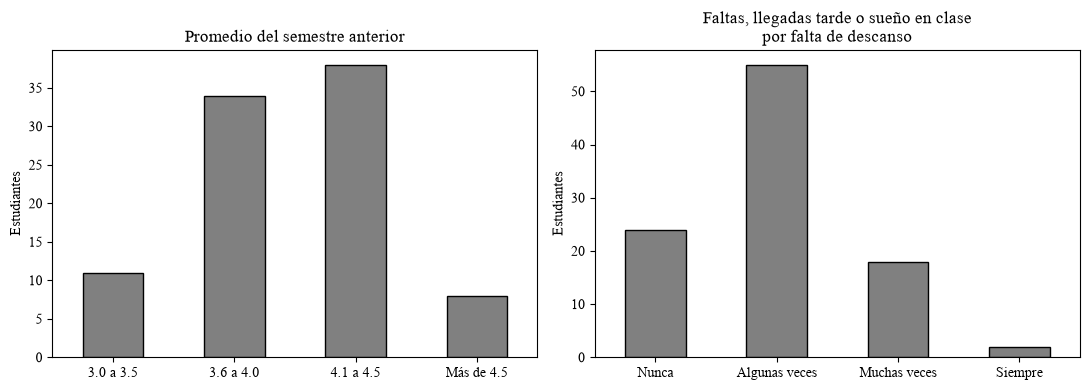

In [12]:
orden_promedio = ["3.0 a 3.5", "3.6 a 4.0", "4.1 a 4.5", "Más de 4.5"]
orden_faltas = ["Nunca", "Algunas veces", "Muchas veces", "Siempre"]

promedio = df["promedio"].value_counts().reindex(orden_promedio)
faltas = df["faltas"].value_counts().reindex(orden_faltas)
print(promedio, "\n"); print(faltas)

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
promedio.plot(kind="bar", ax=ejes[0], color="gray", edgecolor="black", title="Promedio del semestre anterior")
faltas.plot(kind="bar", ax=ejes[1], color="gray", edgecolor="black",
            title="Faltas, llegadas tarde o sueño en clase\npor falta de descanso")
for eje in ejes:
    eje.set_xlabel(""); eje.set_ylabel("Estudiantes"); eje.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## 3. Cruzar variables

Ahora respondemos la pregunta central: **¿el sueño se relaciona con el cansancio y con el rendimiento?**

Para cada cruce se muestra una tabla con la **cantidad** de estudiantes, otra con el **porcentaje dentro de cada fila** y una gráfica de barras apiladas. Se lee así: *"de los estudiantes que tienen calidad de sueño X, ¿qué porcentaje se siente cansado Y?"*.

### 3.1 Calidad de sueño y cansancio en clase

Cantidad de estudiantes:
cansancio  Nunca  Algunas veces  Muchas veces  Siempre
calidad                                               
Muy mala       0              3             9        7
Regular        0             24            19        7
Buena          1             19             3        0
Muy buena      2              4             1        1 

Porcentaje dentro de cada fila:
cansancio  Nunca  Algunas veces  Muchas veces  Siempre
calidad                                               
Muy mala     0.0           16.0          47.0     37.0
Regular      0.0           48.0          38.0     14.0
Buena        4.0           83.0          13.0      0.0
Muy buena   25.0           50.0          12.0     12.0


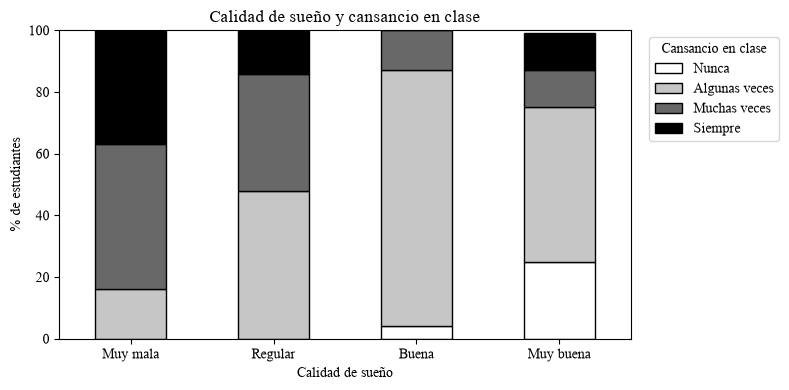

In [13]:
cruce = pd.crosstab(df["calidad"], df["cansancio"]).reindex(index=orden_calidad, columns=orden_cansancio)
print("Cantidad de estudiantes:"); print(cruce, "\n")

porcentaje = (cruce.div(cruce.sum(axis=1), axis=0) * 100).round(0)
print("Porcentaje dentro de cada fila:"); print(porcentaje)

porcentaje.plot(kind="bar", stacked=True, colormap="Greys", edgecolor="black", figsize=(8, 4))
plt.title("Calidad de sueño y cansancio en clase")
plt.xlabel("Calidad de sueño"); plt.ylabel("% de estudiantes"); plt.xticks(rotation=0)
plt.legend(title="Cansancio en clase", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### 3.2 Horas de sueño y cansancio en clase

Cantidad de estudiantes:
cansancio     Nunca  Algunas veces  Muchas veces  Siempre
horas                                                    
Menos de 5 h      0              6            12        8
5 a 7 h           2             39            18        6
7 a 9 h           0              4             2        1
Más de 9 h        0              1             0        0 

Porcentaje dentro de cada fila:
cansancio     Nunca  Algunas veces  Muchas veces  Siempre
horas                                                    
Menos de 5 h    0.0           23.0          46.0     31.0
5 a 7 h         3.0           60.0          28.0      9.0
7 a 9 h         0.0           57.0          29.0     14.0
Más de 9 h      0.0          100.0           0.0      0.0


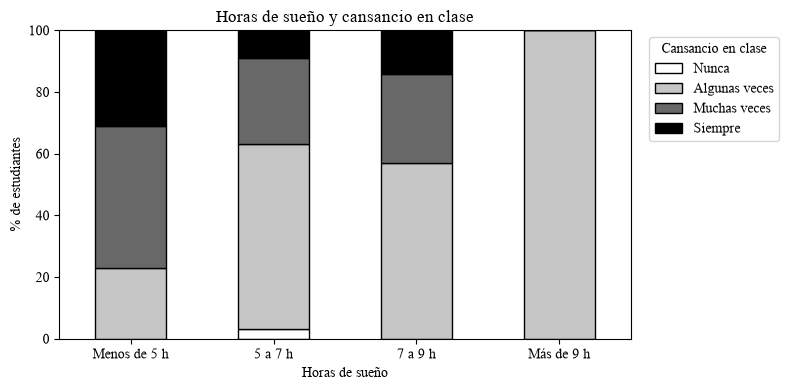

In [14]:
cruce = pd.crosstab(df["horas"], df["cansancio"]).reindex(index=orden_horas, columns=orden_cansancio)
print("Cantidad de estudiantes:"); print(cruce, "\n")

porcentaje = (cruce.div(cruce.sum(axis=1), axis=0) * 100).round(0)
print("Porcentaje dentro de cada fila:"); print(porcentaje)

porcentaje.plot(kind="bar", stacked=True, colormap="Greys", edgecolor="black", figsize=(8, 4))
plt.title("Horas de sueño y cansancio en clase")
plt.xlabel("Horas de sueño"); plt.ylabel("% de estudiantes"); plt.xticks(rotation=0)
plt.legend(title="Cansancio en clase", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### 3.3 Hora de acostarse y calidad de sueño

Cantidad de estudiantes:
calidad             Muy mala  Regular  Buena  Muy buena
hora_acostarse                                         
9 p. m.                    0        1      2          2
9 a 11 p. m.               1       12      9          3
11 p. m. a 1 a. m.         8       26     10          3
1 a 3 a. m.                8        8      2          0
3 a 5 a. m.                2        2      0          0 

Porcentaje dentro de cada fila:
calidad             Muy mala  Regular  Buena  Muy buena
hora_acostarse                                         
9 p. m.                  0.0     20.0   40.0       40.0
9 a 11 p. m.             4.0     48.0   36.0       12.0
11 p. m. a 1 a. m.      17.0     55.0   21.0        6.0
1 a 3 a. m.             44.0     44.0   11.0        0.0
3 a 5 a. m.             50.0     50.0    0.0        0.0


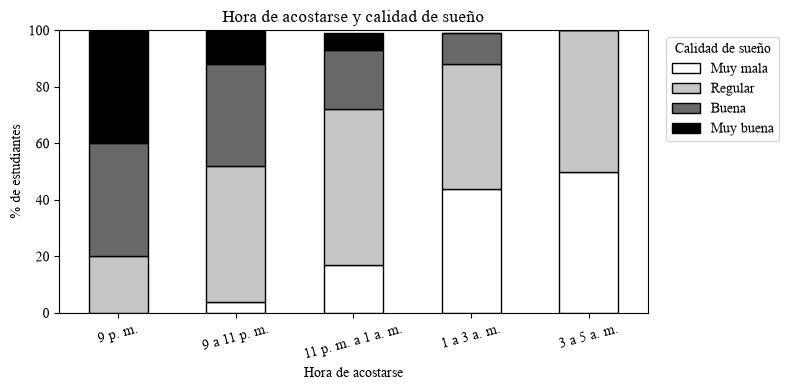

In [15]:
cruce = pd.crosstab(df["hora_acostarse"], df["calidad"]).reindex(index=orden_hora, columns=orden_calidad)
print("Cantidad de estudiantes:"); print(cruce, "\n")

porcentaje = (cruce.div(cruce.sum(axis=1), axis=0) * 100).round(0)
print("Porcentaje dentro de cada fila:"); print(porcentaje)

porcentaje.plot(kind="bar", stacked=True, colormap="Greys", edgecolor="black", figsize=(8, 4))
plt.title("Hora de acostarse y calidad de sueño")
plt.xlabel("Hora de acostarse"); plt.ylabel("% de estudiantes"); plt.xticks(rotation=15)
plt.legend(title="Calidad de sueño", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### 3.4 Calidad de sueño y promedio académico

Cantidad de estudiantes:
promedio   3.0 a 3.5  3.6 a 4.0  4.1 a 4.5  Más de 4.5
calidad                                               
Muy mala           1          8         10           0
Regular            7         16         18           3
Buena              2          6         10           3
Muy buena          1          4          0           2 

Porcentaje dentro de cada fila:
promedio   3.0 a 3.5  3.6 a 4.0  4.1 a 4.5  Más de 4.5
calidad                                               
Muy mala         5.0       42.0       53.0         0.0
Regular         16.0       36.0       41.0         7.0
Buena           10.0       29.0       48.0        14.0
Muy buena       14.0       57.0        0.0        29.0


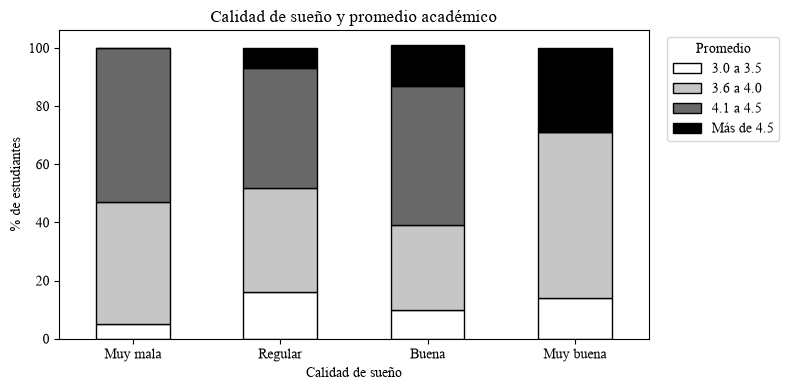

In [16]:
cruce = pd.crosstab(df["calidad"], df["promedio"]).reindex(index=orden_calidad, columns=orden_promedio)
print("Cantidad de estudiantes:"); print(cruce, "\n")

porcentaje = (cruce.div(cruce.sum(axis=1), axis=0) * 100).round(0)
print("Porcentaje dentro de cada fila:"); print(porcentaje)

porcentaje.plot(kind="bar", stacked=True, colormap="Greys", edgecolor="black", figsize=(8, 4))
plt.title("Calidad de sueño y promedio académico")
plt.xlabel("Calidad de sueño"); plt.ylabel("% de estudiantes"); plt.xticks(rotation=0)
plt.legend(title="Promedio", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### 3.5 Horas de sueño y promedio académico

Cantidad de estudiantes:
promedio      3.0 a 3.5  3.6 a 4.0  4.1 a 4.5  Más de 4.5
horas                                                    
Menos de 5 h          0         11         11           1
5 a 7 h               9         20         25           7
7 a 9 h               1          3          1           0
Más de 9 h            0          0          1           0 

Porcentaje dentro de cada fila:
promedio      3.0 a 3.5  3.6 a 4.0  4.1 a 4.5  Más de 4.5
horas                                                    
Menos de 5 h        0.0       48.0       48.0         4.0
5 a 7 h            15.0       33.0       41.0        11.0
7 a 9 h            20.0       60.0       20.0         0.0
Más de 9 h          0.0        0.0      100.0         0.0


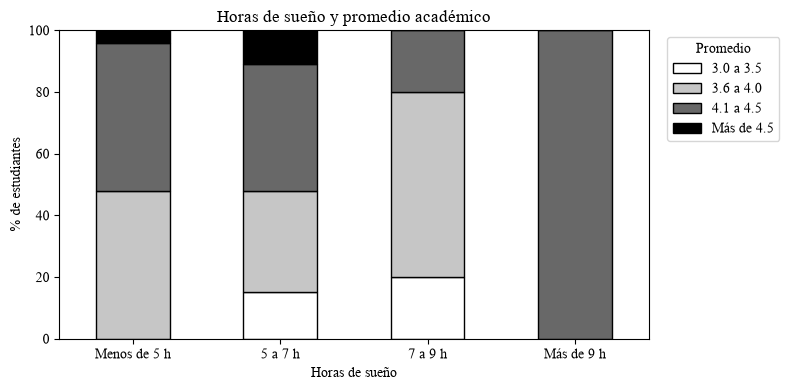

In [17]:
cruce = pd.crosstab(df["horas"], df["promedio"]).reindex(index=orden_horas, columns=orden_promedio)
print("Cantidad de estudiantes:"); print(cruce, "\n")

porcentaje = (cruce.div(cruce.sum(axis=1), axis=0) * 100).round(0)
print("Porcentaje dentro de cada fila:"); print(porcentaje)

porcentaje.plot(kind="bar", stacked=True, colormap="Greys", edgecolor="black", figsize=(8, 4))
plt.title("Horas de sueño y promedio académico")
plt.xlabel("Horas de sueño"); plt.ylabel("% de estudiantes"); plt.xticks(rotation=0)
plt.legend(title="Promedio", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 4. Conclusiones y limitaciones

### Respuesta a la pregunta

Si la UTB tuviera 100 estudiantes (según esta muestra), **la mayoría dormiría poco y con calidad de sueño regular o mala**, y esa mala calidad de sueño se **relaciona con sentirse más cansado en clase**. En cambio, **no se encontró relación entre el sueño y el promedio académico**.

### Qué encontramos

**Cómo duermen**
- **26 de cada 100** duermen menos de 5 horas y **92 de cada 100** duermen menos de 7 horas.
- **69 de cada 100** califican su calidad de sueño como regular o muy mala.
- **47 de cada 100** se sienten cansados en clase muchas veces o siempre.

**Qué les quita el sueño**
- Los **trabajos y tareas** (29) y los **exámenes** (29) son lo que más afecta sus horas de sueño. Les siguen el uso del celular (17), los problemas personales (12), los horarios de clase (9) y el transporte (4).
- **53 de cada 100** se trasnochan casi siempre o siempre para estudiar o entregar trabajos.

**Cómo les afecta el cansancio**
- **58 de cada 100** dicen que el cansancio les dificulta mucho concentrarse, 14 que les cuesta aprender y 12 que afecta considerablemente sus calificaciones. Solo 16 dicen que no les afecta.

**Relaciones más fuertes entre las variables** (correlación de Spearman)

| Relación | Correlación | Cómo se lee |
|---|---|---|
| Acostarse más tarde ↔ dormir menos horas | −0,54 | moderada |
| Mejor calidad de sueño ↔ menos cansancio en clase | −0,50 | moderada |
| Acostarse más tarde ↔ peor calidad de sueño | −0,46 | moderada |
| Trasnocharse más seguido ↔ dormir menos horas | −0,44 | moderada |
| Más cansancio en clase ↔ más faltas o sueño en clase | 0,35 | débil |
| Trasnocharse más seguido ↔ acostarse más tarde | 0,34 | débil |
| Dormir más horas ↔ menos cansancio en clase | −0,33 | débil |

En resumen, **quienes se trasnochan y se acuestan tarde duermen menos y peor, y quienes duermen peor se sienten más cansados en clase**.

### Lo que no encontramos

- **Sueño y promedio:** las correlaciones con el promedio son casi nulas (horas de sueño −0,08; calidad de sueño 0,05; cansancio −0,11). En esta muestra, dormir peor **no se relaciona con tener un promedio más bajo**.
- **Una pista para explorar:** el tiempo de celular antes de dormir tiene una relación débil con el promedio (−0,28): a más tiempo de celular, un promedio algo más bajo. Como se revisaron muchas relaciones a la vez, esto es solo una pista y no una conclusión firme.
- **Una posible explicación (hipótesis):** casi todos tienen promedios entre 3,6 y 4,5 y duermen entre 5 y 7 horas, así que hay muy poca diferencia entre los estudiantes para detectar una relación. Además, **no encontrar una relación no prueba que no exista**.

### Limitaciones

- **No es una muestra representativa de la UTB.** Respondieron personas que tuvieron acceso a la encuesta; el 87 % tiene entre 18 y 22 años y cerca del 60 % estudia ingeniería o ciencia de datos. "Si la UTB tuviera 100 estudiantes" es una forma de presentar los resultados, no una muestra al azar.
- **Son respuestas autorreportadas:** las horas de sueño, la calidad y el promedio dependen de lo que cada persona recuerda o siente. El promedio se preguntó por rangos y 9 personas no lo informaron.
- **Correlación no es causalidad:** vemos que dos cosas van juntas, pero no podemos afirmar que una cause la otra.
- **Pocos casos en algunas categorías** (por ejemplo, dormir 7 horas o más): los porcentajes ahí cambian mucho con una sola persona.
- **Con 100 estudiantes, correlaciones menores a 0,2 (en valor absoluto) pueden deberse al azar.** Este análisis sencillo no incluye pruebas estadísticas, por eso las conclusiones son descriptivas.
- Se recibieron 106 respuestas y se usaron las 100 primeras.